#### Grid Visualization
- Plotting the edges of an unstructured grid
    - Nodes
    - Mesh
    - Edges
- Plotting the coordinates of an unstructured grid
    - Corner Nodes
    - Face Centers
    - Edge Centers 

Ming Ge <br>

Reference:
- https://uxarray.readthedocs.io/en/v2024.01.1/examples/006-plot-api-topology.html
- https://projectpythia.org/unstructured-grid-viz-cookbook/notebooks/03-plotting-with-uxarray/grid-viz.html

In [1]:
%matplotlib inline
import uxarray as ux
import cartopy.crs as ccrs
import geoviews.feature as gf
import holoviews as hv
import warnings
import numpy as np
np.warnings = warnings  # shim: some libs still reference the deprecated np.warnings

In [2]:
data_path = "/glade/campaign/cisl/vast/uxarray/data/e3sm_keeling/ENSO_ctl_1std/unstructured/20231220.F2010.ENSO_ctl.lagreg.ne30pg2_EC30to60E2r2.keeling.eam.h0.0006-12.nc"
grid_file = (
    "/glade/campaign/cisl/vast/uxarray/data/e3sm_keeling/E3SM_grid/ne30pg2_grd.nc"
)
uxds_e3sm = ux.open_dataset(grid_file, data_path)


In [3]:
uxgrid = uxds_e3sm.uxgrid 

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W

CPU times: user 20.4 s, sys: 160 ms, total: 20.5 s
Wall time: 20.7 s


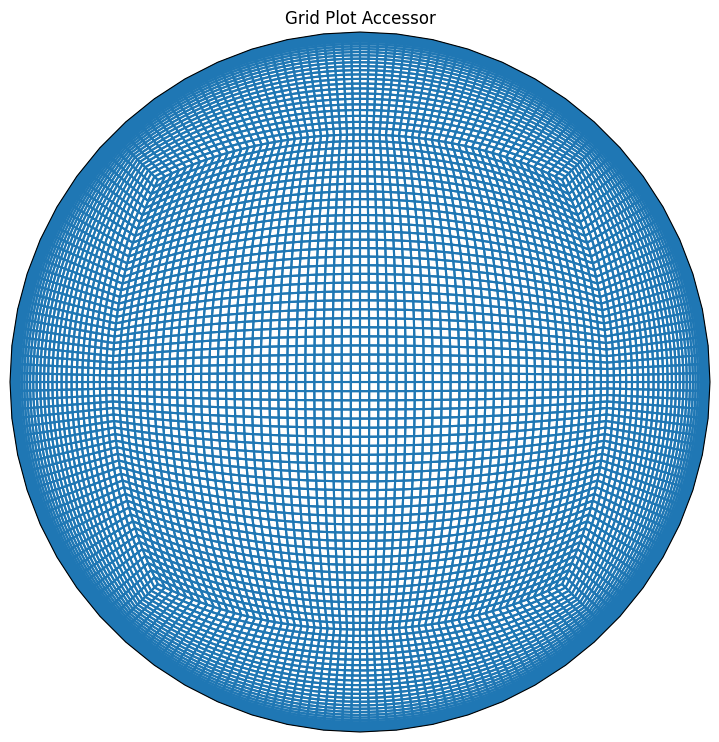

In [4]:
%%time
obj = uxgrid.plot(
    height=500,
    width=750,
    title="Grid Plot Accessor",
    backend="matplotlib",
    projection=ccrs.Orthographic(central_latitude=0, central_longitude=0),
)
hv.render(obj, backend='matplotlib')

#### Plotting Accessor

:Path   [Longitude,Latitude]
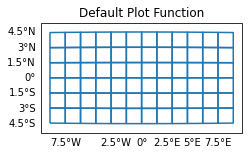

In [5]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot(title="Default Plot Function")

#### Visualizing nodes

:Points   [lon,lat]
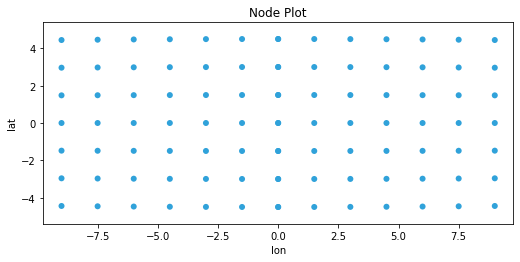

In [6]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.nodes(title="Node Plot")

#### Visualizing Edges

:Path   [Longitude,Latitude]
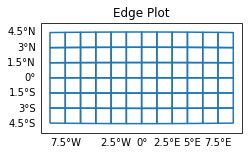

In [7]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.edges(title="Edge Plot")

:Path   [Longitude,Latitude]
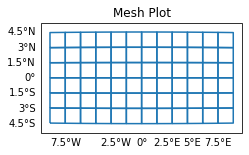

In [8]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.mesh(title="Mesh Plot")

#### Visualizing Coordinates
- Corner Nodes

:Overlay
   .Points.I :Points   [lon,lat]
   .Path.I   :Path   [Longitude,Latitude]
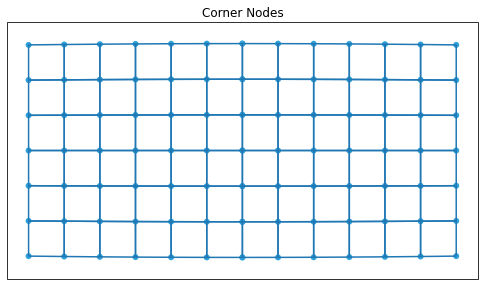

In [9]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.corner_nodes(title="Corner Nodes") * uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot()

- Face Centers

:Overlay
   .Points.I :Points   [lon,lat]
   .Path.I   :Path   [Longitude,Latitude]
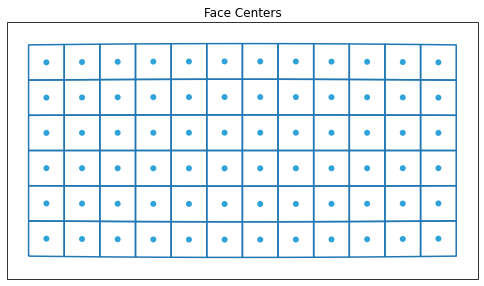

In [10]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.face_centers(title="Face Centers") * uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot()

- Edge Centers

:Overlay
   .Points.I :Points   [lon,lat]
   .Path.I   :Path   [Longitude,Latitude]
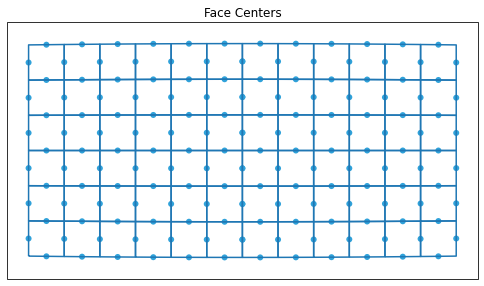

In [11]:
uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.edge_centers(title="Face Centers") * uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot()

#### Plotting Everything Together

:Overlay
   .Path.I              :Path   [Longitude,Latitude]
   .Points.Corner_Nodes :Points   [lon,lat]
   .Points.Face_Centers :Points   [lon,lat]
   .Points.Edge_Centers :Points   [lon,lat]
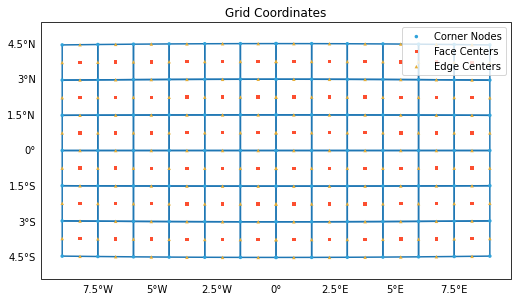

In [12]:
(
    uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.edges(color="black")
    * uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.nodes(marker="o", size=150).relabel("Corner Nodes")
    * uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.face_centers(marker="s", size=150).relabel("Face Centers")
    * uxgrid.subset.bounding_box(lon_bounds = (-10, 10), lat_bounds=(-5, 5)).plot.edge_centers(marker="^", size=150).relabel("Edge Centers")
).opts(title="Grid Coordinates", legend_position="top_right")


#### Zooming in and overlaying both the edge and node plots 

:Overlay
   .Path.I   :Path   [Longitude,Latitude]
   .Points.I :Points   [lon,lat]
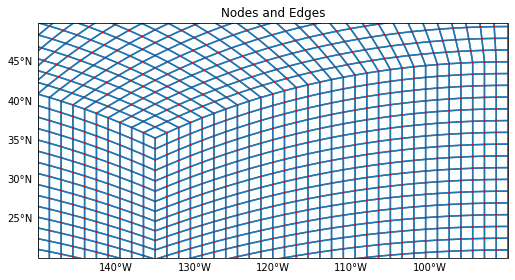

In [13]:
(uxgrid.plot.edges(color="Black") * \
 uxgrid.plot.nodes(color="Red", size=15)).opts(xlim = (-150,-90), ylim = (20, 50), height=350, width=700, title="Nodes and Edges")


#### Visualization Grid Coordinates (Nodes, Edge Centers, & Face Centers)

:Overlay
   .Path.I     :Path   [Longitude,Latitude]
   .Points.I   :Points   [lon,lat]
   .Points.II  :Points   [lon,lat]
   .Points.III :Points   [lon,lat]
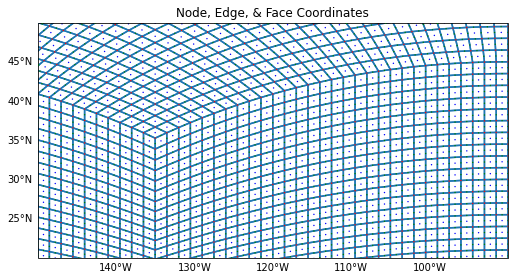

In [14]:
# exclude_antimeridian=False keeps dateline-crossing polygons intact instead of splitting them
(uxgrid.plot.mesh(color="Black", line_dash='dashed', line_width=2, exclude_antimeridian=False) * \
 uxgrid.plot.nodes(color = "Red", size=4) * \
 uxgrid.plot.face_centers(color = "Blue",  size=4) * \
 uxgrid.plot.edge_centers(color = "Green",  size=4)).opts(title="Node, Edge, & Face Coordinates", xlim=(-150,-90), ylim=(20, 50), width=700, height=350)


:Overlay
   .Path.I     :Path   [Longitude,Latitude]
   .Points.I   :Points   [lon,lat]
   .Points.II  :Points   [lon,lat]
   .Points.III :Points   [lon,lat]
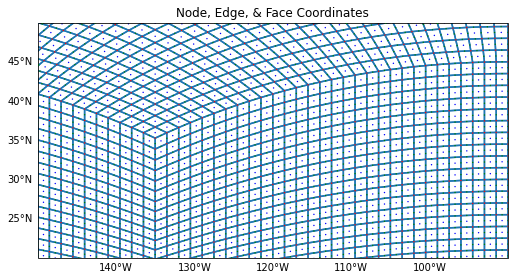

In [15]:
# exclude_antimeridian=False keeps dateline-crossing polygons intact instead of splitting them
(uxgrid.plot.mesh(color="Black", line_dash='dashed', line_width=2, exclude_antimeridian=False) * \
 uxgrid.plot.node_coords(color = "Red", size=4) * \
 uxgrid.plot.face_coords(color = "Blue",  size=4) * \
 uxgrid.plot.edge_coords(color = "Green",  size=4)).opts(title="Node, Edge, & Face Coordinates", xlim=(-150,-90), ylim=(20, 50), width=700, height=350)


#### MPAS Voronoi Mesh
no color for edges 
https://uxarray.readthedocs.io/en/v2024.01.1/examples/006-plot-api-topology.html

In [16]:
base_path = "/glade/work/mingge/MPAS/"
grid_path = base_path + "mesh.QU.1920km.151026.nc"
primal_grid = ux.open_grid(grid_path, use_dual=False)
dual_grid = ux.open_grid(grid_path, use_dual=True)  # Voronoi dual: vertices become dual-cell centers

:Overlay
   .Path.I    :Path   [Longitude,Latitude]
   .Points.I  :Points   [lon,lat]
   .Path.II   :Path   [Longitude,Latitude]
   .Points.II :Points   [lon,lat]
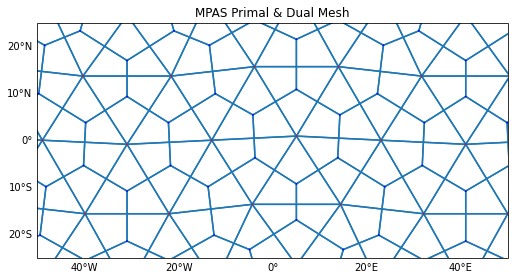

In [17]:
(primal_grid.plot.edges(color="Blue") * \
 primal_grid.plot.nodes(color="Blue", size=10) * \
 dual_grid.plot.edges(color="Red", size=20) * \
 dual_grid.plot.nodes(color="Red", size=10)).opts(title="MPAS Primal & Dual Mesh", xlim=(-50, 50), ylim=(-25, 25))
